# INF8775 – Analyse et conception d’algorithmes
# TP2 – Automne 2026

NOM, Prénom, 1234567

NOM, Prénom, 1234567

Note finale :

 <u>**Date limite de remise :**</u>  8 novembre 23h59 (Groupe 1), 10 novembre 23h59 (Groupe 2)

# Instructions

## Rédaction et remise du rapport

- Ce notebook constitue à la fois le sujet du TP, votre code et votre rapport. Il contient déjà du code pour faciliter vos mesures et l'affichage de vos résultats, ainsi qu'un squelette pour votre rapport.

- Complétez directement le notebook, vous êtes libres de créer de nouvelles cellules de code ou de texte. 

- Remettez le fichier du notebook sur Moodle avec le nom `NOM1_MATRICULE1_NOM2_MATRICULE2.ipynb`

- Vous pouvez inclure du code trouvé sur Internet, mais vous devez en mentionner la source, sous peine d'être sanctionnés pour plagiat.

## Mise en situation

Ce travail pratique se répartit sur deux séances de laboratoire et porte sur l'analyse et la conception d'algorithmes développés suivant différents patrons de conception afin de résoudre une version simplifiée d'un problème réaliste d'optimisation.


## Description du problème

Un pianiste souhaite jouer une mélodie donnée par une partition. La mélodie est une suite de n notes *(a0, a1, ... , an-1)* où chaque ai appartient à un ensemble de m notes numérotées de 0 à m-1.

Le pianiste peut choisir de jouer chaque note avec l’un de ses D doigts. Le passage de la note i1 jouée avec le doigt d1 à la note i2 jouée avec le doigt d2 est pénalisée par une fonction de difficulté de la transition *C(i1, d1, i2, d2)*. Notre pianiste souhaite donc déterminer avec quel doigt il doit jouer chaque note de la mélodie de façon à minimiser la somme des coûts de chaque transition.

Pour la partie empirique de ce TP, nous nous limiterons à des mélodies jouées à une main (D=5) sur deux octaves (m=24).

Soit l’exemple suivant avec 5 notes :

- L'exemplaire est : `[17, 21, 18, 2, 21, 15, 11, 16]`
- La solution est : `[2, 1, 1, 0, 1, 1, 2, 1]`

La figure ci-dessous représente la partition avec ça solution et le coût associé à chaque transition.

![alt text](example_solution.png "Title")

## Algorithmes à implanter

Trois algorithmes seront implantés, mettant en pratique des patrons de conception différents :

1. Un algorithme glouton
2. Un algorithme de programmation dynamique
3. Un algorithme de recherche locale


## Jeu de données

La fonction `generate_sample` ci-dessous permet de générer un exemplaire d'une taille donnée.

La fonction `get_dataset` permet de récupérer un dataset pour la liste de taille fournie. Elle prend également en entrée un graine aléatoire pour générer le dataset en question.

Afin que chaque groupe travaille avec un set différent, mais que vos propres expériences soient reproductibles, entrez l'un de vous matricule comme graine aléatoire dans la cellule ci-dessous.

Vous êtes bien entendu libres de tester et mesurer vos algorithme sur le même dataset qu'un autre groupe. Pour cela, générez simplement un dataset avec la même graine et la même liste de taille.



In [23]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from scipy.stats import linregress
import time

In [24]:
def visualize_solution(costs, partition, solution):
    """
    Visualisez votre solution et les coûts associés.    
    """
    # Create a figure and axis
    _, ax = plt.subplots()
    
    # Plot the notes as circles with their sizes proportional to the partition values
    for i in range(len(partition)):
        ax.scatter([i], [partition[i]], marker='o')
        ax.text(i, partition[i] + 0.2, str(solution[i]), ha='center', va='bottom')
    
    # Set the limits for the axes to fit the plot
    ax.set_ylim(min(partition) - 1, max(partition) + 1)
    ax.set_xlim(-0.5, len(partition)-0.5)
    
    # Label the axes
    ax.set_xlabel('Partition')
    ax.set_ylabel('Note')
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    
    # Title the plot
    ax.set_title('Partition et doigts utilisés')

    plot_costs = getCosts(costs, partition, solution).tolist()
    plot_costs.append(0)

    ax2 = ax.twinx()
    ax2.bar(range(len(partition)), plot_costs, width=1, alpha=0.5, align='edge', color='gray')
    ax2.set_xlim(-0.5, len(partition)-0.5)
    ax2.set_ylim(0, 100)
    
    # Remove the ticks and tick labels from the secondary y-axis
    ax2.tick_params(axis='both', which='both', length=0)
    ax2.set_yticklabels([])
    ax2.spines['top'].set_visible(False)
    ax2.spines['right'].set_visible(False)
    ax2.spines['bottom'].set_visible(False)
    ax2.spines['left'].set_visible(False)    
    # Show the plot
    plt.show()

def generate_sample(size, maxValue=24):
    return np.random.randint(0, maxValue, size).tolist()

def get_dataset(seed, sizes):
    np.random.seed(seed)
    return { size: [generate_sample(size) for _ in range(5)]
        for size in sizes }

def readFile(filePath):
    """
    Charger une partition depuis un fichier
    """
    f = open(filePath)
    N = int(f.readline())
    partition = list(map(int, f.readline().split(' ')))
    f.close()
    return partition

def getCosts(costs, partition, solution):
    """
    Liste des coûts associés à chaque transition de votre solution.
    """
    prevNotes, nextNotes = partition[:-1], partition[1:]
    prevFingers, nextFingers = solution[:-1], solution[1:]
    return costs[prevNotes, prevFingers, nextNotes, nextFingers]

def getTotalCost(costs, partition, solution):
    """
    Coût total de votre solution
    """
    return np.sum(getCosts(costs, partition, solution))

Exécutez la cellule suivante afin d'obtenir le tenseur des coûts associé à chaque transition.

In [ ]:
load_file = np.loadtxt('cout_transition.txt', dtype=int)
costs = load_file.reshape((24, 5, 24, 5))
D = 5    # Nombre de doigts
M = 24   # Etendue des notes (2 octaves)

partition = readFile('Chansons/fur_elise.txt')
#partition = readFile('Chansons/twinkle_twinkle.txt')

# Implantations et expérimentations

Ces fonctions auxiliaires vous sont fournies pour vérifier l'exactitude des vos algorithmes, mesurer leurs performance et afficher vos résultats.

Il est recommandé de prendre le temps de lire et comprendre le code.

Exécutez la cellule ci-dessous pour pouvoir utiliser les fonctions auxiliaires.

In [26]:
def measure(procedure, sample):
    """ Mesure le temps d'execution d'une procédure sur un unique exemplaire """
    start = time.time()
    solution = procedure(sample)
    end = time.time()
    sorting_time = end - start
    return solution, sorting_time


def measure_mean_time(procedure, samples):
    total_time = 0
    for i in range(len(samples)):
        sample = samples[i]
        _, compute_time = measure(procedure, sample)
        total_time += compute_time
        print(f"Computing {procedure.__name__} on sample {i+1} of size {len(sample)}...          ", end='\r')
    return total_time / len(samples)


def measure_procedure(procedure, dataset):
    """ Mesure les temps moyens d'execution d'une procédure sur chaque point d'un dataset """
    return {size: measure_mean_time(procedure, samples) for size, samples in dataset.items()}

def display_measures_table(measures):
    print("{: <12} {: <12}".format("Taille", "Temps moyen (s)"))
    for size, measure in measures.items():
        print("{: <12} {: <12}".format(size, measure))


def display_test_puissance(vals, title="Test de puissance"):
    x = list(vals.keys())
    y = list(vals.values())

    # Perform linear regression
    m, b, rvalue, _, _ = linregress(x, y)
    r = list(map(lambda x : m*x + b, x))

    # Create the line equation
    line_eq = f"y = {m:.2f}x + {b:.2f}"

    # Plot the points
    plt.scatter(x, y, label='Mesures')

    # Plot the regression line
    plt.plot(x, r, color="red", label=f'Regression linéaire R²={round(rvalue**2,4)}')

    # Add labels and title
    plt.xlabel('log Taille')
    plt.ylabel('log Temps')
    plt.title(title)

    # Add legend
    plt.legend(bbox_to_anchor=(0.60, 0), loc='lower left')

    # Display the line equation
    plt.text(min(x), max(y), line_eq)

    # Show the plot
    plt.show()

def display_test_rapport(vals, title="Test du rapport"):
    x = list(vals.keys())
    y = list(vals.values())

    plt.plot(x, y, label='Mesures')
    plt.scatter(x, y, label='Mesures')

    # Add labels and title
    plt.xlabel('Taille')
    plt.ylabel('Temps / f(taille)')
    plt.title(title)
    plt.show()


def display_test_constantes(vals, title="Test des constantes"):
    x = list(vals.keys())
    y = list(vals.values())

    # Perform linear regression
    m, b, rvalue, _, _ = linregress(x, y)

    r = list(map(lambda x : m*x + b, x))

    # Create the line equation
    line_eq = f"y = {m:.2E}x + {b:.2E}"

    # Plot the points
    plt.scatter(x, y, label='Mesures')

    # Plot the regression line
    plt.plot(x, r, color="red", label=f'Regression linéaire R²={round(rvalue**2,4)}')

    # Add labels and title
    plt.xlabel('f(Taille)')
    plt.ylabel('Temps')
    plt.title(title)

    # Add legend
    plt.legend(bbox_to_anchor=(0.60, 0), loc='lower left')

    # Display the line equation
    plt.text(min(x), max(y), line_eq)

    # Show the plot
    plt.show()

## Partie 1 : Algorithme glouton

Implantez un algorithme suivant le patron de conception glouton.

L'algorithme glouton fait son choix en fonction du coût de la prochaine transition :

Les deux premiers doigts d0 et d1 sont choisis de façon à minimiser C(a0, d0, a1, d1). Puis, étant donné le
doigt précédent d et la transition de la note i vers la note j, le choix glouton porte sur le doigt d’ qui
minimise C(i, d, j, d’).

Tentez de rendre votre implantation la plus performante possible en évitant des calculs inutiles.

Coût Glouton : 2022


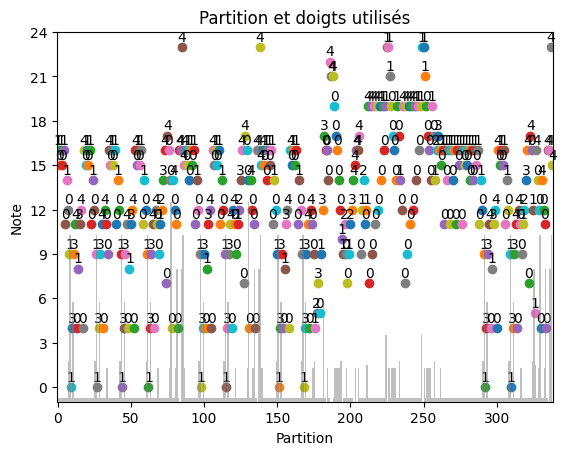

In [27]:
def glouton(partition):
    n = len(partition)
    solution = [0] * n
    if n < 2:
        return solution

    # Trouver les deux premiers doigts
    first = costs[partition[0], :, partition[1], :]
    d0, d1 = np.unravel_index(np.argmin(first), first.shape)
    solution[0], solution[1] = int(d0), int(d1)

    for k in range(1, n - 1):
        row = costs[partition[k], solution[k], partition[k + 1], :]
         # Choisir le doigt au coût minimum
        solution[k + 1] = int(np.argmin(row))

    return solution

solutionGlouton = glouton(partition)
print("Coût Glouton :", getTotalCost(costs, partition, solutionGlouton))
visualize_solution(costs, partition, solutionGlouton)

### Analyse asymptotique

Dans cette analyse, vous tiendrez compte à la fois de la longueur de la mélodie mais également du
nombre de doigts pour chacun des trois algorithmes.

On considère **n** comme le nombre de notes dans la mélodie et **D** comme le nombre de doigts disponibles.

Au début, on initialise une liste de taille n pour stocker les doigts choisis, ce qui prend **Θ(n)**.

Ensuite, pour les deux premières notes, on cherche la meilleure combinaison de doigts. Comme chaque note peut être jouée avec D doigts, on a D × D combinaisons à vérifier. Cette étape prend donc **Θ(D²)**.

Pour les notes suivantes, on parcourt les n − 2 notes restantes. À chaque fois, on garde le doigt précédent et on cherche le doigt qui donne le plus petit coût parmi les D possibilités. Cette partie prend donc **Θ((n − 2)D)**.

La complexité totale est :

$$
T(n,D)=\Theta(n+D^2+(n-2)D)
$$

En simplifiant, on obtient :

$$
\boxed{T(n,D)=\Theta(D^2+nD)}
$$

Dans notre TP, on utilise toujours 5 doigts (D = 5). La complexité devient donc **Θ(n)**, ce qui veut dire que le temps d'exécution augmente de façon linéaire avec le nombre de notes.

Pour l'espace mémoire, on utilise principalement la liste `solution` de taille n, donc **Θ(n)**.

Finalement, l'algorithme glouton ne garantit pas toujours la meilleure solution globale, puisqu'il choisit à chaque étape le doigt avec le coût le plus faible sans tenir compte des transitions suivantes.

### Mesures

Rapportez dans un tableau les temps d'exécutions moyens avec les fonctions auxiliaires `measure_procedure` et `display_measure_table`

In [ ]:
SEED = 2155059
sizes = [5000 * i for i in range(1, 11)]
dataset = get_dataset(SEED, sizes)

_ = glouton(dataset[sizes[-1]][0]) #warmup

measuresGlouton = measure_procedure(glouton, dataset)
display_measures_table(measuresGlouton)


Taille       Temps moyen (s)5 of size 50000...          
5000         0.012569618225097657
10000        0.029022932052612305
15000        0.05049819946289062
20000        0.054378604888916014
25000        0.059387588500976564
30000        0.07307043075561523
35000        0.08383803367614746
40000        0.09759521484375
45000        0.11100072860717773
50000        0.12582526206970215


### Validation empirique

Servez-vous de vos temps d'exécution pour confirmer et/ou préciser l'analyse asymptotique théorique de vos algorithmes avec la méthode hybride de votre choix.

La méthode peut varier d'un algorithme à l'autre. Justifiez les choix ici et avec des graphiques. Vous ne devez donc pas utiliser les 3 tests pour chaque algorithme, mais plutôt choisir la ou les méthodes les plus appropriées pour chacun d'eux.

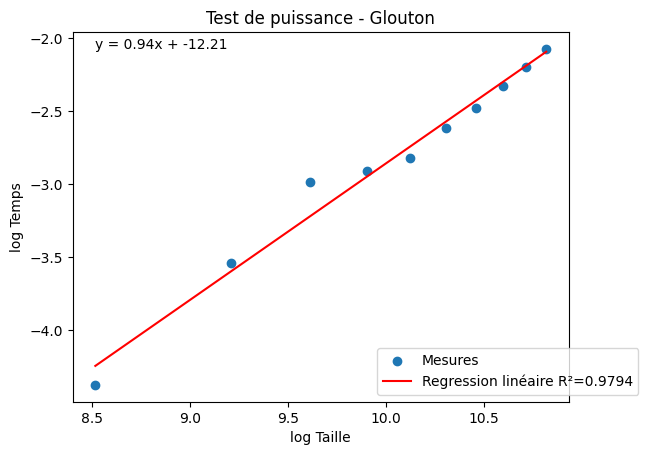

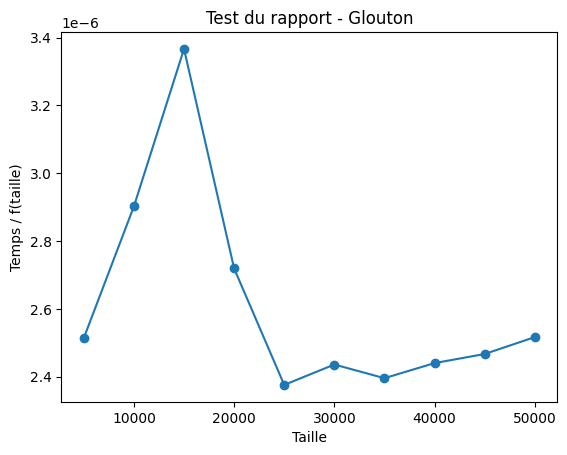

In [52]:

# Test de puissance
mesuresLog = {
    np.log(n): np.log(t)
    for n, t in measuresGlouton.items()
}

display_test_puissance(mesuresLog, title="Test de puissance - Glouton")


# Test du rapport T(n)/n
rapportGlouton = {n: t / n for n, t in measuresGlouton.items()}
display_test_rapport(rapportGlouton, title="Test du rapport - Glouton")


Dans notre analyse théorique, on a trouvé une complexité de Θ(nD), soit Θ(n) puisque D = 5 est constant. Pour vérifier cela, on a choisi le test de puissance et le test du rapport. Le premier permet de voir si la croissance est proche de n, tandis que le deuxième permet de vérifier si le rapport entre le temps et la taille reste constant.

Test de puissance : On obtient une pente de 0,94 avec un R² de 0,98. Comme la pente est proche de 1, cela correspond à une croissance linéaire. On remarque quelques écarts entre les points et la droite, surtout pour les tailles intermédiaires. Ces différences peuvent venir des variations dans les temps d'exécution.

Test du rapport : Avec f(n) = n, on remarque quelques variations au début, notamment autour de n = 15 000. Par la suite, le rapport T(n)/n se stabilise autour de 2,4 × 10⁻⁶ à 2,5 × 10⁻⁶ s/note pour les grandes tailles. Cela montre que le temps d'exécution est à peu près proportionnel au nombre de notes.

Conclusion : Les deux tests donnent des résultats cohérents avec notre analyse théorique. On peut donc dire que les mesures soutiennent une complexité de Θ(n) pour l'algorithme glouton lorsque D = 5.

## Partie 2 : Algorithme de programmation dynamique

L'algorithme de programmation dynamique remplit un tableau des coûts de transition optimaux en
fonction de la mélodie.

Notons `J(k, d)` la somme minimale des coût de transition associée à la mélodie `(ak, ... , an−1)` (c’est-à-
dire au suffixe de longueur `n - k` de la mélodie de départ) où l’on joue la première note ak avec le doigt
d.

Alors, J vérifie la relation de récurrence (1) :

J(k, d) = min { 0≤ d’ ≤ D-1} [ C(ak, d, ak+1, d’ ) + J(k + 1, d’ ) ]

et la condition terminale (2) :

J(n - 1, d) = 0, ∀d = 0, ... , D - 1

Comme on ne connaît pas le premier doigt à utiliser a priori, la solution au problème original est
donnée par (3) :

min { 0 ≤ d ≤ D-1} J(0, d)

Cette récurrence est résolue par programmation dynamique pour déterminer la solution au problème.
Note : Pour vous aider à vérifier que votre implantation fonctionne correctement, voici deux solutions
que vous devriez obtenir avec cet algorithme (dépendant de votre implantation, il pourrait être possible
que vous arriviez au même coût, mais avec une différente suite de doigts) :

- twinkle_twinkle.txt ; coût = 31; doigts = [0, 0, 4, 3, 4, 4, 3, 2, 2, 1, 1, 0, 1, 0, 4, 4, 3, 3, 2, 2, 0, 4, 4, 3,
3, 2, 2, 1, 0, 0, 4, 3, 4, 4, 3, 2, 2, 1, 1, 0, 1, 0]

- fur_elise.txt ; coût = 1091; doigts = [1, 0, 1, 0, 1, 0, 4, 4, 4, 0, 1, 4, 4, 0, 1, 3, 4, 0, 4, 0, 1, 0, 1, 0, 4, 4,
4, 0, 1, 4, 4, 0, 4, 3, 0, 4, 0, 1, 0, 1, 0, 4, 4, 4, 0, 1, 4, 4, 0, 1, 3, 4, 0, 4, 0, 1, 0, 1, 0, 4, 4, 4, 0, 1, 4, 4, 0,4, 3, 0, 1, 2, 3, 4, 0, 4, 4, 4, 0, 4, 4, 4, 0, 4, 3, 3, 3, 4, 0, 1, 0, 1, 0, 1, 0, 4, 4, 4, 0, 1, 4, 0, 1, 3, 4, 0, 4, 0,
1, 0, 1, 0, 4, 4, 4, 0, 1, 4, 4, 0, 4, 3, 0, 1, 2, 3, 4, 0, 4, 4, 4, 0, 4, 4, 4, 0, 4, 3, 3, 3, 4, 0, 1, 0, 1, 0, 1, 0, 4,
4, 4, 0, 1, 4, 0, 1, 3, 4, 0, 4, 0, 1, 0, 1, 0, 4, 4, 4, 0, 1, 4, 4, 0, 4, 3, 2, 0, 1, 2, 0, 1, 0, 2, 1, 1, 0, 4, 4, 4, 3,
2, 1, 0, 1, 0, 0, 2, 1, 0, 0, 1, 2, 3, 3, 4, 3, 4, 0, 1, 2, 0, 0, 4, 0, 4, 0, 4, 0, 4, 0, 4, 0, 1, 0, 4, 4, 4, 4, 3, 2, 1,
0, 4, 3, 1, 0, 4, 0, 4, 0, 4, 0, 4, 0, 4, 0, 1, 0, 4, 4, 4, 4, 3, 2, 1, 0, 2, 1, 0, 1, 2, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1,
0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 4, 4, 4, 0, 1, 4, 4, 0, 1, 3, 4, 0, 4, 0, 1, 0, 1, 0, 4, 4, 4, 0, 1, 4,
4, 0, 4, 3, 0, 1, 2, 3, 4, 0, 4, 4, 4, 0, 4, 4, 4, 0, 4, 4, 4, 0, 4, 4, 4, 4]

Implantez l'algorithme de programmation dynamique.

Coût Programmation Dynamique : 1091


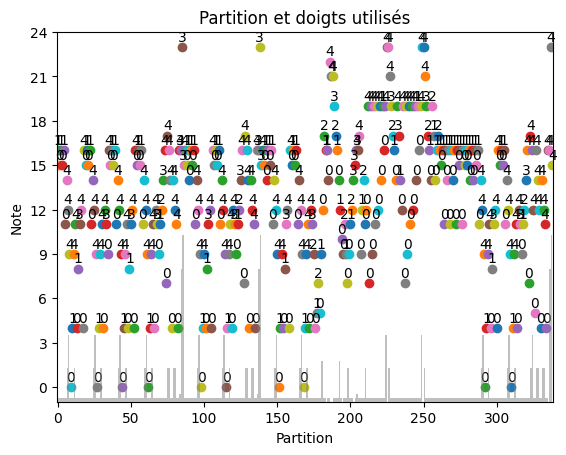

In [ ]:
def progDyn(partition):
    solution = [0 for i in range(len(partition))]

    n = len(partition)
    if n < 2:
        return solution

    D = costs.shape[1]  

    # Condition terminale (2) : J(n-1, d) = 0 pour tout d
    J = np.zeros(D)
   
    choice = np.empty((n - 1, D), dtype=np.int64)
    
    for k in range(n - 2, -1, -1):
       
        M = costs[partition[k], :, partition[k + 1], :] + J
        choice[k] = np.argmin(M, axis=1)   
        J = np.min(M, axis=1)              # nouveau J(k, d)

   
    solution[0] = int(np.argmin(J))
    for k in range(n - 1):
        solution[k + 1] = int(choice[k, solution[k]])
    return solution

solutionDyn = progDyn(partition)
print("Coût Programmation Dynamique :", getTotalCost(costs, partition, solutionDyn))
visualize_solution(costs, partition, solutionDyn)

### Analyse asymptotique

Dans cette analyse, vous tiendrez compte à la fois de la longueur de la mélodie mais également du
nombre de doigts pour chacun des trois algorithmes.

Soit n le nombre de notes dans la mélodie et D le nombre de doigts.

Pour commencer, on initialise la liste `solution` de taille n, ce qui prend Θ(n). On crée aussi un tableau `choice` de taille (n − 1) × D pour garder les doigts choisis.

Ensuite, on parcourt les n − 1 positions en partant de la fin. À chaque position, on calcule les coûts pour les D doigts actuels et les D doigts suivants. On a donc D × D possibilités à considérer, ce qui prend Θ(D²) par position.

La complexité totale pour cette partie est donc Θ(nD²).

Finalement, on parcourt une dernière fois la mélodie pour reconstruire la solution, ce qui prend Θ(n).

**La complexité temporelle totale est :**

$$
T(n,D) = \Theta(n + nD + nD^2 + n)
$$

En simplifiant :

$$
T(n,D) = \Theta(nD^2)
$$

Comme D = 5 dans notre TP, on obtient :

$$
T(n) = \Theta(n)
$$


Contrairement au glouton, la programmation dynamique permet de trouver le coût total minimum, car elle prend en compte les coûts des transitions suivantes avant de choisir les doigts.

### Mesures

Rapportez dans un tableau les temps d'exécutions moyens avec les fonctions auxiliaires `measure_procedure` et `display_measure_table`

In [53]:
SEED = 2155059
sizes = [5000 * i for i in range(1, 11)]
dataset = get_dataset(SEED, sizes)

# Warm-up (caches, fréquence CPU) avant de mesurer
_ = progDyn(dataset[sizes[-1]][0])

measuresDyn = measure_procedure(progDyn, dataset)
display_measures_table(measuresDyn)

Taille       Temps moyen (s)5 of size 50000...          
5000         0.06738405227661133
10000        0.13088078498840333
15000        0.23956618309020997
20000        0.22494359016418458
25000        0.3055544376373291
30000        0.3561097621917725
35000        0.4241529941558838
40000        0.4780221462249756
45000        0.5313032150268555
50000        0.5871311664581299


### Validation empirique

Servez-vous de vos temps d'exécution pour confirmer et/ou préciser l'analyse asymptotique théorique de vos algorithmes avec la méthode hybride de votre choix.

La méthode peut varier d'un algorithme à l'autre. Justifiez les choix ici et avec des graphiques. Vous ne devez donc pas utiliser les 3 tests pour chaque algorithme, mais plutôt choisir la ou les méthodes les plus appropriées pour chacun d'eux.

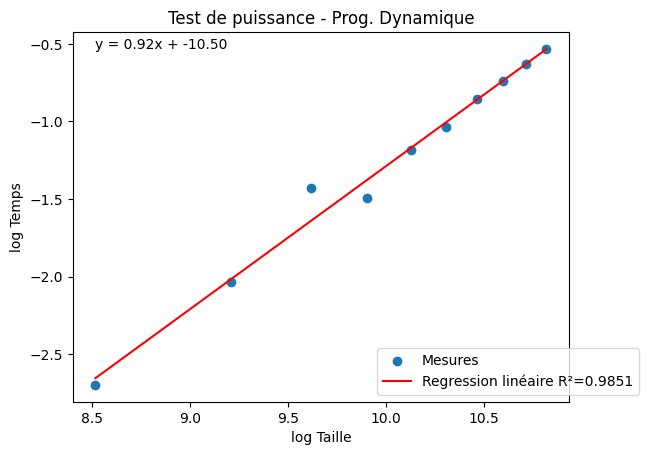

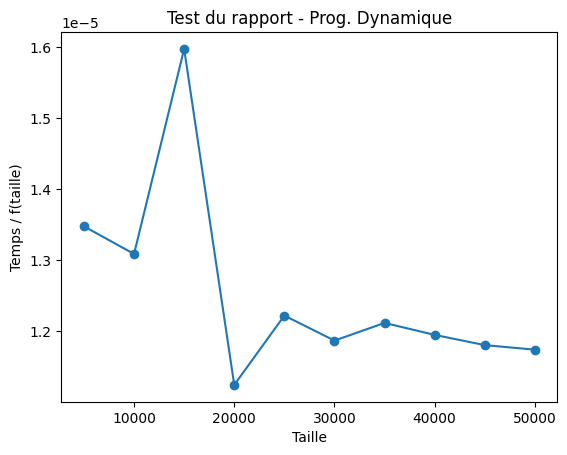

In [54]:
# Test de puissance (log-log) 
mesuresLogDyn = {np.log(n): np.log(t) for n, t in measuresDyn.items()}
display_test_puissance(mesuresLogDyn, title="Test de puissance - Prog. Dynamique")

# Test du rapport 
rapportDyn = {n: t / n for n, t in measuresDyn.items()}
display_test_rapport(rapportDyn, title="Test du rapport - Prog. Dynamique")

*Insérer votre réponse ici*

## Partie 3 : Algorithme de recherche locale

Cet algorithme explore le voisinage de solutions non optimales. En partant d’une solution gloutonne, la
solution est améliorée en tentant d’échanger un doigt pour un autre sur une note. Vous pourrez prendre
comme critère d’arrêt un nombre maximal d’itérations.

Coût Recherche Locale : 1524


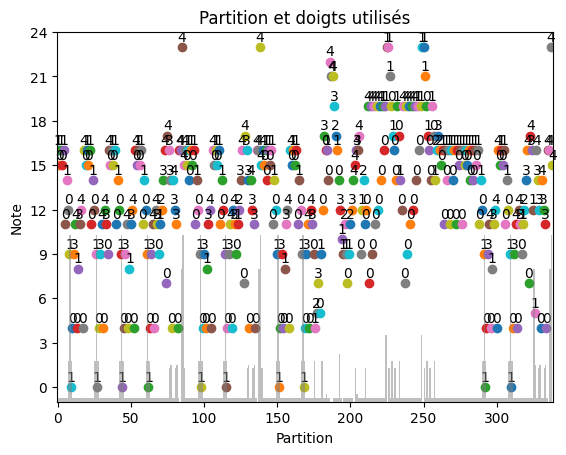

In [56]:
def localSearch(partition, max_iterations=100):
    n = len(partition)
    if n < 2:
        return [0] * n

    D = costs.shape[1]

    # Solution initiale : glouton
    solution = glouton(partition)

    for _ in range(max_iterations):
        improved = False
        for i in range(n):
            # delta[d] = somme des coûts des transitions touchées si la note i est jouée avec d
            delta = np.zeros(D)
            if i > 0:
                delta += costs[partition[i - 1], solution[i - 1], partition[i], :]
            if i < n - 1:
                delta += costs[partition[i], :, partition[i + 1], solution[i + 1]]

            best = int(np.argmin(delta))
            if delta[best] < delta[solution[i]]:
                solution[i] = best   # échange de doigt améliorant
                improved = True

        if not improved:
            break   # optimum local atteint : aucun échange n'améliore

    return solution



solutionLocal = localSearch(partition)
print("Coût Recherche Locale :", getTotalCost(costs, partition, solutionLocal))
visualize_solution(costs, partition, solutionLocal)

### Analyse asymptotique

Dans cette analyse, vous tiendrez compte à la fois de la longueur de la mélodie mais également du
nombre de doigts pour chacun des trois algorithmes.

*Insérer votre réponse ici*

### Mesures

Rapportez dans un tableau les temps d'exécutions moyens avec les fonctions auxiliaires `measure_procedure` et `display_measure_table`

### Validation empirique

Servez-vous de vos temps d'exécution pour confirmer et/ou préciser l'analyse asymptotique théorique de vos algorithmes avec la méthode hybride de votre choix.

La méthode peut varier d'un algorithme à l'autre. Justifiez les choix ici et avec des graphiques. Vous ne devez donc pas utiliser les 3 tests pour chaque algorithme, mais plutôt choisir la ou les méthodes les plus appropriées pour chacun d'eux.

*Insérer votre réponse ici*

# Conclusion et synthèse

Résumez succintement vos résultats et indiquez sous quelles conditions vous utiliseriez chacun des algorithmes.

*Insérer votre réponse ici*